<a href="https://colab.research.google.com/github/mateosanlu/MachineLearning/blob/main/ML_Algoritmo_Inmuebles_PCA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

1. Importar Librerías

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA



In [ ]:
# 1. Cargar el dataset
from google.colab import files
files.upload()

# Usamos sep=";" porque las columnas están delimitadas por punto y coma
# Usamos encoding="latin1" para leer correctamente caracteres como la ñ o tildes
df = pd.read_csv("DATASET_INmuebles.csv", sep=";", encoding="latin1")

# El identificador real en el archivo es "Inmueble"
ids = df["Inmueble"]

# Ajustamos los nombres de las variables para que coincidan exactamente con las del archivo
variables_numericas = [
    "Precio arriendo",
    "Área m²",
    "Habitaciones",
    "Baños",
    "Antig[uedad"
]

variables_categoricas = ["Localidad"]

X = df[variables_numericas + variables_categoricas]


In [ ]:
# 2. Preprocesamiento

# Limpiar la columna 'Precio arriendo' quitando los puntos de miles y convirtiendo a float
X = X.copy()
X["Precio arriendo"] = X["Precio arriendo"].astype(str).str.replace(".", "", regex=False).astype(float)

preprocesamiento = ColumnTransformer(
    transformers=[
        ("numericas", StandardScaler(), variables_numericas),
        ("categoricas",
         OneHotEncoder(handle_unknown="ignore"),
         variables_categoricas)
    ]
)

X_preparado = preprocesamiento.fit_transform(X)

In [ ]:

# 3. Experimento A: K-Means sobre los datos preprocesados
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

grupos = kmeans.fit_predict(X_preparado)

df["Grupo_KMeans"] = grupos


In [ ]:
# 4. PCA para representar los datos en dos dimensiones
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_preparado)

print("Dimensiones originales después del preprocesamiento:",
      X_preparado.shape)

print("Dimensiones después de PCA:", X_pca.shape)

print("Varianza explicada por componente:",
      pca.explained_variance_ratio_)

print("Varianza acumulada:",
      pca.explained_variance_ratio_.sum())


Dimensiones originales después del preprocesamiento: (1000, 8)
Dimensiones después de PCA: (1000, 2)
Varianza explicada por componente: [0.45105709 0.17756495]
Varianza acumulada: 0.6286220379358065


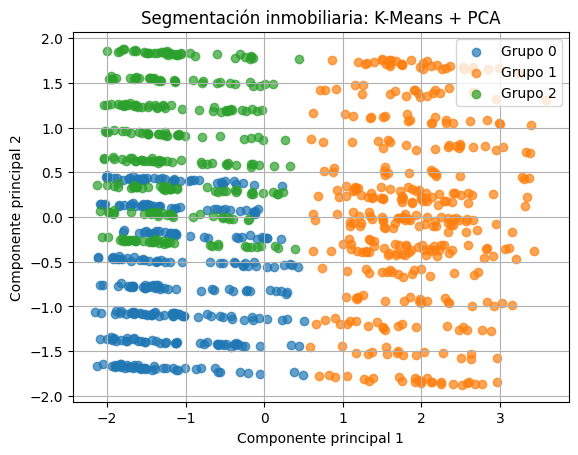

In [ ]:

# 5. Gráfica de los grupos
for grupo in sorted(df["Grupo_KMeans"].unique()):
    seleccion = grupos == grupo

    plt.scatter(
        X_pca[seleccion, 0],
        X_pca[seleccion, 1],
        label=f"Grupo {grupo}",
        alpha=0.7
    )

plt.xlabel("Componente principal 1")
plt.ylabel("Componente principal 2")
plt.title("Segmentación inmobiliaria: K-Means + PCA")
plt.legend()
plt.grid(True)
plt.show()



In [ ]:
# 6. Perfil comercial de los grupos

# Asegurar que las variables numéricas sean de tipo numérico en el dataframe original df
# Limpiamos 'Precio arriendo' convirtiéndola a float quitando los puntos de miles
df["Precio arriendo"] = df["Precio arriendo"].astype(str).str.replace(".", "", regex=False).astype(float)

# Convertimos el resto de variables numéricas por si hay alguna cargada como texto
for var in variables_numericas:
    df[var] = pd.to_numeric(df[var], errors='coerce')

print(
    df.groupby("Grupo_KMeans")[
        variables_numericas
    ].mean().round(2)
)

# Distribución por localidad dentro de cada grupo
print(pd.crosstab(
    df["Grupo_KMeans"],
    df["Localidad"],
    normalize="index"
).round(2))

              Precio arriendo  Área m²  Habitaciones  Baños  Antig[uedad
Grupo_KMeans                                                            
0                  2063615.30    62.21          1.87    1.0         8.60
1                  6353185.81   156.07          4.03    1.5         8.31
2                  1974711.38    60.85          1.84    2.0         8.49
Localidad     Chapinero  Suba  Usaquén
Grupo_KMeans                          
0                  0.34  0.35     0.32
1                  0.31  0.31     0.38
2                  0.36  0.35     0.29
